In [8]:
!pip install nltk

In [9]:
import nltk
nltk.download('reuters')
nltk.download('gutenberg')
nltk.download('stopwords')
nltk.download('punkt')
nltk.download('punkt_tab' )
nltk.download('udhr')


[nltk_data] Downloading package reuters to /root/nltk_data...
[nltk_data]   Package reuters is already up-to-date!
[nltk_data] Downloading package gutenberg to /root/nltk_data...
[nltk_data]   Package gutenberg is already up-to-date!
[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!
[nltk_data] Downloading package punkt to /root/nltk_data...
[nltk_data]   Package punkt is already up-to-date!
[nltk_data] Downloading package punkt_tab to /root/nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!
[nltk_data] Downloading package udhr to /root/nltk_data...
[nltk_data]   Package udhr is already up-to-date!


True

In [10]:
# Task 1
from nltk.corpus import reuters, gutenberg
print("Reuters files (sample):", reuters.fileids())
print("Gutenberg files (sample):", gutenberg.fileids(), "\n")

Reuters files (sample): ['test/14826', 'test/14828', 'test/14829', 'test/14832', 'test/14833', 'test/14839', 'test/14840', 'test/14841', 'test/14842', 'test/14843', 'test/14844', 'test/14849', 'test/14852', 'test/14854', 'test/14858', 'test/14859', 'test/14860', 'test/14861', 'test/14862', 'test/14863', 'test/14865', 'test/14867', 'test/14872', 'test/14873', 'test/14875', 'test/14876', 'test/14877', 'test/14881', 'test/14882', 'test/14885', 'test/14886', 'test/14888', 'test/14890', 'test/14891', 'test/14892', 'test/14899', 'test/14900', 'test/14903', 'test/14904', 'test/14907', 'test/14909', 'test/14911', 'test/14912', 'test/14913', 'test/14918', 'test/14919', 'test/14921', 'test/14922', 'test/14923', 'test/14926', 'test/14928', 'test/14930', 'test/14931', 'test/14932', 'test/14933', 'test/14934', 'test/14941', 'test/14943', 'test/14949', 'test/14951', 'test/14954', 'test/14957', 'test/14958', 'test/14959', 'test/14960', 'test/14962', 'test/14963', 'test/14964', 'test/14965', 'test/149

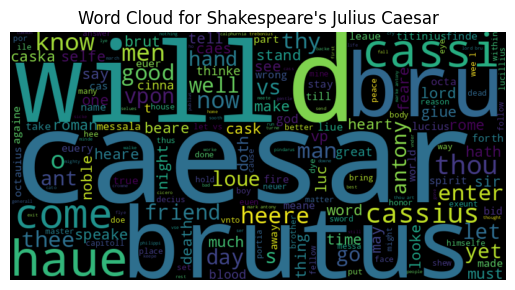

In [11]:
#Task2
from wordcloud import WordCloud
import matplotlib.pyplot as plt
from nltk.tokenize import word_tokenize

caesar_text = gutenberg.raw('shakespeare-caesar.txt')
tokens = word_tokenize(caesar_text.lower())
wordcloud = WordCloud(width=800, height=400).generate(' '.join(tokens))

plt.imshow(wordcloud, interpolation='bilinear')
plt.axis('off')
plt.title("Word Cloud for Shakespeare's Julius Caesar")
plt.show()


Top 17 after preprocessing: [('the', 37), ('of', 30), (',', 29), ('.', 26), ('to', 26), ('u.s.', 17), ('and', 16), ('said', 16), ('in', 16), ('trade', 15), ('a', 15), ('japan', 12), ("'s", 12), ('for', 7), ('``', 7), ("''", 7), ('on', 6)]
Top 17 after preprocessing: [('trade', 16), ('said', 16), ('japan', 12), ('export', 11), ('import', 6), ('dlr', 6), ('tariff', 5), ('billion', 5), ('businessmen', 4), ('offici', 4), ('might', 4), ('would', 4), ('japanes', 4), ('electron', 4), ('industri', 4), ('taiwan', 4), ('also', 4)]


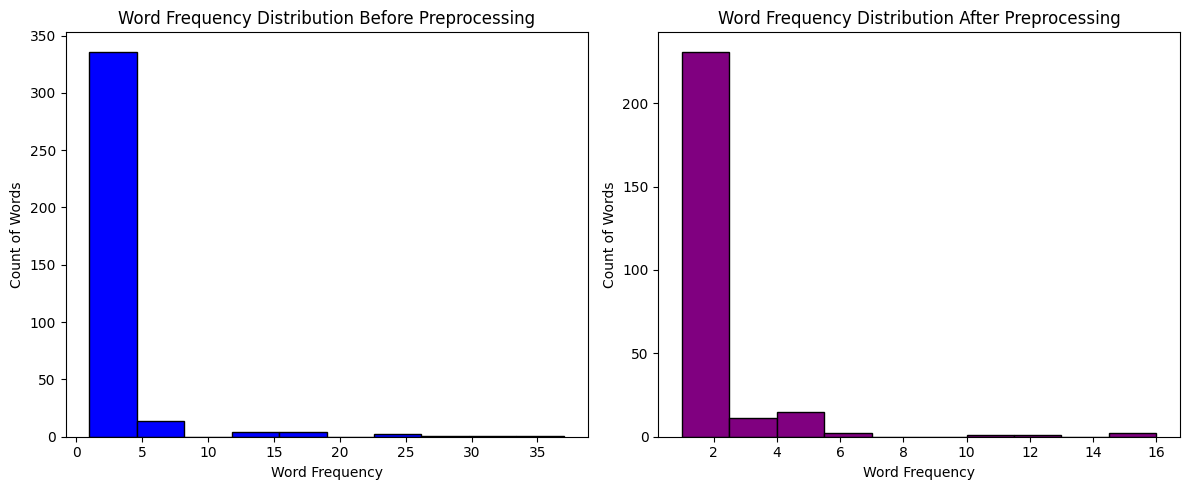

In [12]:
#Task3
import nltk
from nltk.corpus import reuters, stopwords
from nltk.tokenize import word_tokenize
from nltk.stem import PorterStemmer
from collections import Counter
import matplotlib.pyplot as plt

text = reuters.raw('test/14826')
words = word_tokenize(text.lower())

word_counts_before = Counter(words)
top17_before = word_counts_before.most_common(17)
print("Top 17 after preprocessing:", top17_before)

stop_words = set(stopwords.words('english'))
stemmer = PorterStemmer()
filtered = [stemmer.stem(word) for word in words if word.isalnum() and word not in stop_words]
top17_after = Counter(filtered).most_common(17)
print("Top 17 after preprocessing:", top17_after)

word_counts_after = Counter(filtered)
top17_after = word_counts_after.most_common(17)

freq_values_before = list(word_counts_before.values())
freq_values_after = list(word_counts_after.values())

plt.figure(figsize=(12, 5))
plt.subplot(1, 2, 1)
plt.hist(freq_values_before, bins=10, color='blue', edgecolor='black')
plt.title("Word Frequency Distribution Before Preprocessing")
plt.xlabel("Word Frequency")
plt.ylabel("Count of Words")

plt.subplot(1, 2, 2)
plt.hist(freq_values_after, bins=10, color='purple', edgecolor='black')
plt.title("Word Frequency Distribution After Preprocessing")
plt.xlabel("Word Frequency")
plt.ylabel("Count of Words")

plt.tight_layout()
plt.show()


In [13]:
#Task4
from nltk import bigrams
from collections import Counter
from nltk.tokenize import word_tokenize
import html
import re

all_words = []
for file_id in reuters.fileids()[:100]:
    text = reuters.raw(file_id)
    text = html.unescape(text)
    words = word_tokenize(text.lower())
    words = [re.sub(r'[^a-z0-9]', '', word) for word in words]
    words = [word for word in words if word.strip()]
    all_words.extend(words)

bigram_list = list(bigrams(all_words))
bigram_freq = Counter(bigram_list).most_common(70)

print("\nTop 70 Bigrams (Reuters):")
for bg in bigram_freq[:70]:
    print(f"{bg[0][0]} {bg[0][1]}: {bg[1]}")


Top 70 Bigrams (Reuters):
of the: 96
in the: 85
said the: 63
the us: 45
he said: 44
said it: 39
for the: 36
the company: 30
to the: 29
mln dlrs: 25
cts vs: 25
billion dlrs: 24
said he: 24
first quarter: 23
mln stg: 23
in a: 22
last year: 21
would be: 21
the first: 21
on the: 21
mln vs: 21
to be: 20
has been: 20
this year: 20
in 1986: 19
will be: 18
and the: 18
of a: 18
by the: 17
in 1985: 17
said in: 17
expected to: 17
at the: 16
they said: 16
cts net: 16
that the: 15
said they: 15
dlrs in: 15
with the: 14
due to: 14
it said: 14
dlrs a: 14
the shares: 14
net shr: 14
japan s: 13
the government: 13
it has: 13
company s: 13
1st qtr: 13
it will: 12
pct of: 12
south korea: 12
palm oil: 12
told reuters: 12
a share: 12
to a: 11
said a: 11
is expected: 11
pct in: 11
at a: 11
spokesman said: 11
from the: 11
san miguel: 11
hong kong: 10
because of: 10
for a: 10
tonnes of: 10
it is: 10
a statement: 10
billion marks: 10


In [14]:
#Task5
from nltk.corpus import udhr
from nltk.tokenize import word_tokenize

spanish_text = udhr.raw('Spanish-Latin1')

vowels = {'a', 'e', 'i', 'o', 'u', 'á', 'é', 'í', 'ó', 'ú', 'ü'}

trigram_counts = Counter()

words = word_tokenize(spanish_text)

for word in words:
    consonants = [c.lower() for c in word if c.isalpha() and c.lower() not in vowels]
    for i in range(len(consonants) - 2):
        trigram = tuple(consonants[i:i+3])
        trigram_counts[trigram] += 1

print("Top Consonant Trigrams:")
for tg, count in trigram_counts.most_common():
    print(f"{''.join(tg)}: {count}")


Top Consonant Trigrams:
drc: 55
rch: 53
prs: 36
mnt: 35
rtc: 34
rsn: 32
ncn: 31
cns: 27
ccn: 26
tcl: 26
lbr: 25
ntr: 22
tds: 17
chs: 16
cnc: 16
rmn: 16
rcn: 15
brt: 15
rtd: 15
mbr: 14
prt: 14
cnl: 13
hmn: 12
trs: 12
mns: 11
prc: 11
cnt: 11
stn: 11
cmn: 10
rnc: 10
pbl: 10
ldd: 10
scl: 10
tnc: 10
trr: 10
rtr: 10
rnd: 9
trn: 9
fnd: 9
dnt: 9
nst: 9
lgn: 9
str: 9
mtr: 9
drn: 8
ndd: 8
sts: 8
std: 8
sgr: 8
tnt: 8
tcn: 8
trb: 8
clr: 7
rsl: 7
prm: 7
nsd: 7
sdr: 7
gnd: 7
sfr: 7
ncs: 7
cmp: 7
dmn: 7
ntl: 7
lmn: 7
clq: 7
lqr: 7
ndc: 7
tcc: 7
trm: 7
dcl: 6
rcl: 6
tnn: 6
brs: 6
fml: 6
nts: 6
hmb: 6
mpl: 6
frm: 6
mpr: 6
ctv: 6
cnd: 6
pnd: 6
nld: 6
rbj: 6
nvr: 5
vrs: 5
ncm: 5
dgn: 5
bls: 5
dsc: 5
spr: 5
rgn: 5
cts: 5
srs: 5
frt: 5
ncl: 5
nds: 5
ndm: 5
fct: 5
ndv: 5
dvd: 5
dcc: 5
rlg: 5
dcn: 5
ndn: 5
trc: 5
scr: 5
nfr: 5
prv: 5
vln: 5
pdr: 5
blc: 5
rrs: 5
cls: 5
lrc: 4
clm: 4
gls: 4
mmb: 4
scn: 4
dsf: 4
crn: 4
crs: 4
tls: 4
jrs: 4
grs: 4
mtd: 4
mdn: 4
tvs: 4
rrt: 4
dst: 4
pnn: 4
rdc: 4
dpn: 4
trt: 4
gr